This exercise seeks to implement a generic policy improvement (PI) agent to a 4x4 grid with obstacles (XX), terminal positive states (+1) and terminal negative states (-1)

For example

|     |     |     |     |
|:---:|:---:|:---:|:---:|
| +1  |  0  |  0  | XX  |
| -1  |  0  | XX  |  0  |
|  0  |  0  |  0  |  0  |
|  0  |  0  |  0  |  0  |

For simplicity let's make the transitions deterministic, i.e $$p(s' | s,a) = 1$$

The agent tries to learn the value of each cell, so that we can plot a heat map of the grid
We also plot the action-value function, by specifying arrows for each cell.

In [81]:
import numpy as np

In [82]:
#states = np.array([-1,0,0,"XX"],[0,"XX",0,0],[0,0,0,0],[0,"XX",0,1]) # deterministic case
states = np.array([
    [-1, 0, 0, 1],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, -1, 0, 1]
])

state_coordinates = [
    (row, col)
    for row in range(states.shape[0])
    for col in range(states.shape[1])
]

terminal_states = [s for s in state_coordinates if abs(states[s[0],s[1]]) == 1]

In [83]:
actions = [
    (-1, 0),  # up
    (1, 0),   # down
    (0, -1),  # left
    (0, 1)    # right
]

policy = {
    state: actions[np.random.choice(len(actions))]
    for state in state_coordinates
    if state not in terminal_states
}
# initialize the policy randomly for each state

In [84]:
def get_reward(state: tuple):
    return states[state]


def get_next_state(state: tuple, action: tuple):
    """
    Returns the next state after taking a specific action.
    If the action would leave the grid, remain in the same state.
    """

    if state in terminal_states:
        return state

    row, col = state
    drow, dcol = action

    new_row = row + drow
    new_col = col + dcol

    if (
        0 <= new_row < states.shape[0]
        and 0 <= new_col < states.shape[1]
    ):
        return (new_row, new_col)

    return state


def step(state: tuple):
    """
    Follow the current policy pi from state s.
    """

    action = policy[state]

    return get_next_state(state, action)

For a deterministic example $$ \sum_a \pi(a|s)=1$$ so

In [85]:
V = {
    state: float(get_reward(state))
    if state in terminal_states
    else 0.0
    for state in state_coordinates
}

gamma = 0.99


def get_value(state):

    # Terminal states already have their fixed value
    if state in terminal_states:
        return get_reward(state)

    next_state = step(state)
    reward = get_reward(next_state)

    if next_state in terminal_states:
        return reward

    return reward + gamma * V[next_state]

def policy_evaluation(theta=1e-6):

    while True:

        delta = 0

        for state in state_coordinates:

            if state in terminal_states:
                continue

            old_value = V[state]

            new_value = get_value(state)

            V[state] = new_value

            delta = max(
                delta,
                abs(new_value - old_value)
            )

        if delta < theta:
            break

In [86]:
def policy_improvement():

    policy_stable = True

    for state in state_coordinates:

        if state in terminal_states:
            continue

        old_action = policy[state]

        q_values = {}

        for action in actions:

            next_state = get_next_state(state, action)
            reward = get_reward(next_state)

            if next_state in terminal_states:
                q_values[action] = reward

            else:
                q_values[action] = (
                    reward
                    + gamma * V[next_state]
                )

        best_action = max(
            q_values,
            key=q_values.get
        )

        policy[state] = best_action

        if best_action != old_action:
            policy_stable = False

    return policy_stable


In [89]:
while True:

    policy_evaluation()

    stable = policy_improvement()

    if stable:
        break

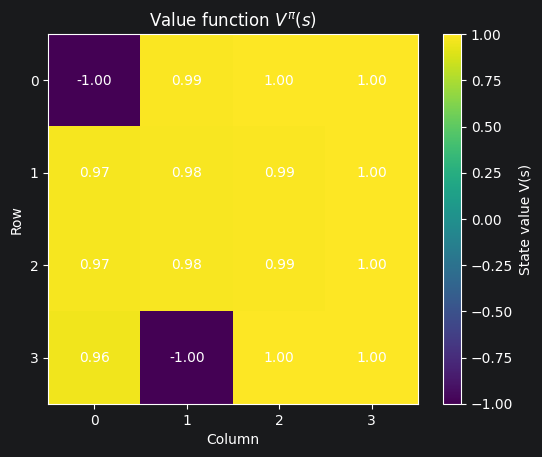

In [90]:
import matplotlib.pyplot as plt
import numpy as np

# Run policy evaluation first
policy_evaluation()

# Convert the V dictionary into a 2D array
V_grid = np.zeros(states.shape)

for state, value in V.items():
    V_grid[state] = value

# Plot heatmap
plt.imshow(V_grid)
plt.colorbar(label="State value V(s)")

# Write values inside cells
for row in range(V_grid.shape[0]):
    for col in range(V_grid.shape[1]):
        plt.text(
            col,
            row,
            f"{V_grid[row, col]:.2f}",
            ha="center",
            va="center"
        )

plt.xticks(range(states.shape[1]))
plt.yticks(range(states.shape[0]))
plt.xlabel("Column")
plt.ylabel("Row")
plt.title(r"Value function $V^\pi(s)$")
plt.show()

if your non-terminal cells have reward 0, then the value essentially becomes “how good is this location in terms of where the policy eventually takes me?” So yes, the heatmap is showing future expected outcome, not the immediate cell reward.

Important distinction : The PI algorithm evaluates the whole state space, whereas an episode starts from an initial state and stops when reaching a terminal state

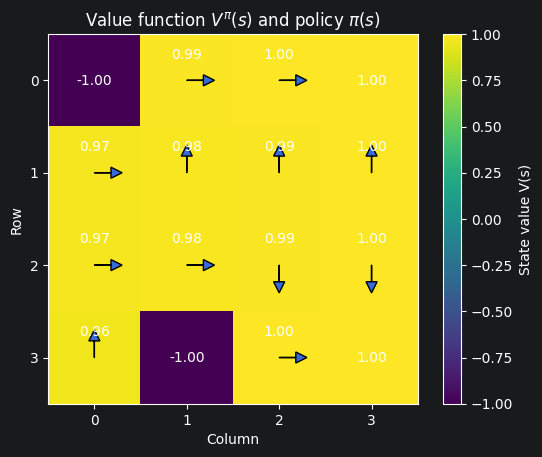

In [91]:
import matplotlib.pyplot as plt
import numpy as np

V_grid = np.zeros(states.shape)

for state, value in V.items():
    V_grid[state] = value

plt.imshow(V_grid)
plt.colorbar(label="State value V(s)")

for state in state_coordinates:

    row, col = state

    if state in terminal_states:
        plt.text(
            col, row,
            f"{V[state]:.2f}",
            ha="center",
            va="center"
        )
        continue

    drow, dcol = policy[state]

    plt.arrow(
        col,
        row,
        dcol * 0.3,
        drow * 0.3,
        head_width=0.12,
        head_length=0.12,
        length_includes_head=True
    )

    plt.text(
        col,
        row - 0.28,
        f"{V[state]:.2f}",
        ha="center",
        va="center"
    )

plt.xticks(range(states.shape[1]))
plt.yticks(range(states.shape[0]))
plt.xlabel("Column")
plt.ylabel("Row")
plt.title(r"Value function $V^\pi(s)$ and policy $\pi(s)$")
plt.show()

Next task : implement a non-deterministic case. The agent might not move to the desired location but instead slip to one of the adjacent blocs.
